# Baseline

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import re
import statsmodels.formula.api as smf
from pathlib import Path

# project root
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'clean').is_dir())
CLEAN = ROOT / 'clean' / 'election_results'

panel = pd.read_csv(CLEAN / 'ohio_county_panel.csv')
FORECAST_OUT = ROOT / 'output' / 'forecast'
FORECAST_OUT.mkdir(parents=True, exist_ok=True)

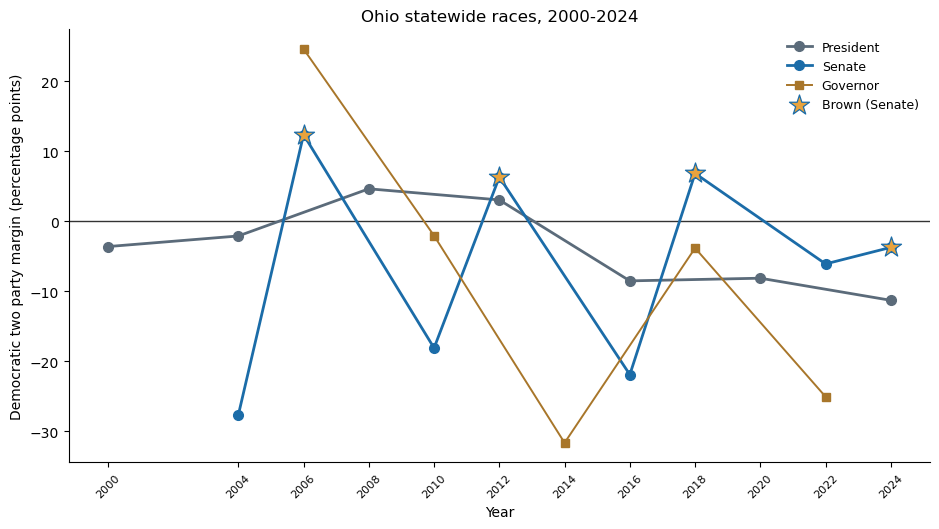

In [2]:
# AI was used to create this graph
# Figure 1: Ohio statewide races, Dem two party margin
def statewide(off, yr):
    s, v = panel[f'dem2p_{off}_{yr}'], panel[f'votes_{off}_{yr}']
    return (2 * (s * v).sum() / v.sum() - 1) * 100       # percentage points

rows = []
for c in panel.columns:
    m = re.fullmatch(r'dem2p_(pres|sen|gov)_(\d{4})', c)
    if m and f'votes_{m.group(1)}_{m.group(2)}' in panel.columns:
        rows.append({'office': m.group(1), 'year': int(m.group(2)),
                     'margin': statewide(m.group(1), int(m.group(2)))})
mg = pd.DataFrame(rows).sort_values('year')
BROWN = [2006, 2012, 2018, 2024]

fig, ax = plt.subplots(figsize=(9.5, 5.4))
style = {'pres': ('President', '#5b6b7a', 'o', 2.0, 7),
         'sen':  ('Senate',    '#1b6ca8', 'o', 2.0, 7),
         'gov':  ('Governor',  '#a8762a', 's', 1.4, 6)}
for off, (lab, col, mk, lw, ms) in style.items():
    dd = mg[mg.office == off]
    ax.plot(dd.year, dd.margin, mk + '-', color=col, lw=lw, ms=ms, label=lab)

bs = mg[(mg.office == 'sen') & mg.year.isin(BROWN)]
ax.scatter(bs.year, bs.margin, s=230, marker='*', color='#e8a33d',
           edgecolor='#1b6ca8', linewidth=.9, zorder=5, label='Brown (Senate)')

ax.axhline(0, color='#333', lw=1, zorder=0)
ax.set_xticks(sorted(mg.year.unique()))
ax.tick_params(axis='x', labelrotation=45, labelsize=8)
ax.set(xlabel='Year', ylabel='Democratic two party margin (percentage points)',
       title='Ohio statewide races, 2000-2024')
ax.legend(frameon=False, fontsize=9)
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(ROOT / 'output' / 'ohio_statewide_races.png', dpi=100)
plt.show()

In [3]:
# regression data: Senate races 2000-2024 + Ohio 2026 row
PANEL = pd.read_csv(CLEAN / 'baseline_panel.csv')
lean = PANEL[PANEL.dem2p_sen.notna()].reset_index(drop=True)
X26 = PANEL[PANEL.year == 2026].iloc[0]

def fit_on(df, formula):
    # OLS, SEs clustered by state
    return smf.ols(formula, df).fit(cov_type='cluster', cov_kwds={'groups': df.state_po})

def forecast(fit, x):
    return fit.params['Intercept'] + sum(fit.params[k] * v for k, v in x.items() if k in fit.params)

X_OH_2026_BASE = {'lean': X26.lean, 'midD': 0, 'midR': 1, 'S_lag': X26.S_lag}
print(len(lean), 'races')

423 races


In [4]:
# Table 2
T2 = {'(1)': fit_on(lean, 'dem2p_sen ~ lean'),
      '(2)': fit_on(lean, 'dem2p_sen ~ lean + midD + midR'),
      '(3)': fit_on(lean.dropna(subset=['S_lag']), 'dem2p_sen ~ lean + midD + midR + S_lag')}
print(pd.DataFrame({k: m.params for k, m in T2.items()}).round(3))
print(pd.DataFrame({k: m.bse for k, m in T2.items()}).round(3))
# R2, N, 2026 Ohio margin (pp)
pd.DataFrame({k: {'R2': m.rsquared, 'N': m.nobs, 'margin_2026': (2 * forecast(m, X_OH_2026_BASE) - 1) * 100}
              for k, m in T2.items()}).round(3)

             (1)    (2)    (3)
Intercept  0.520  0.523  0.453
S_lag        NaN    NaN  0.145
lean       0.991  0.988  0.846
midD         NaN -0.030 -0.038
midR         NaN  0.023  0.024
             (1)    (2)    (3)
Intercept  0.007  0.007  0.051
S_lag        NaN    NaN  0.096
lean       0.056  0.057  0.125
midD         NaN  0.007  0.007
midR         NaN  0.010  0.011


,(1),(2),(3)
R2,0.531,0.550,0.613
N,423.000,423.000,373.000
margin_2026,-5.646,-0.592,1.155


In [5]:
# baseline = column (3); prediction SE: sqrt(x'Vx + sigma^2)
BASELINE = T2['(3)']
x = np.array([1.0 if k == 'Intercept' else X_OH_2026_BASE[k] for k in BASELINE.params.index])
share = x @ BASELINE.params.values
se_share = np.sqrt(x @ BASELINE.cov_params().values @ x + BASELINE.mse_resid)
margin, se_margin = (2 * share - 1) * 100, 2 * se_share * 100
print(round(margin, 2), round(se_margin, 2))

b = BASELINE.params
pd.DataFrame([{'share': share, 'margin_pp': margin, 'se_margin_pp': se_margin, 'b0': b.Intercept,
               'b_lean': b.lean, 'b_midD': b.midD, 'b_midR': b.midR, 'b_S_lag': b.S_lag,
               'r2': BASELINE.rsquared, 'nobs': BASELINE.nobs, 'lean_OH': X26.lean,
               'S_lag_OH': X26.S_lag}]).to_csv(FORECAST_OUT / 'baseline_forecast.csv', index=False)

1.16 16.39


In [6]:
# Table 5, second row: (3) + incumbency (+1 D, -1 R, 0 open)
INC_MODEL = fit_on(lean.dropna(subset=['S_lag']), 'dem2p_sen ~ lean + midD + midR + S_lag + inc')
print(INC_MODEL.params.round(3), round(INC_MODEL.rsquared, 3), INC_MODEL.nobs)
# 2026 Ohio: Husted open seat vs. incumbent
m_open = (2 * forecast(INC_MODEL, {**X_OH_2026_BASE, 'inc': 0}) - 1) * 100
m_inc = (2 * forecast(INC_MODEL, {**X_OH_2026_BASE, 'inc': -1}) - 1) * 100
print(round(m_open, 1), round(m_inc, 1))
pd.DataFrame([{**INC_MODEL.params, 'margin_pp_open': m_open, 'margin_pp_incumbent': m_inc,
               'r2': INC_MODEL.rsquared, 'nobs': INC_MODEL.nobs}]).to_csv(FORECAST_OUT / 'incumbency_model.csv', index=False)

Intercept    0.498
lean         0.657
midD        -0.041
midR         0.008
S_lag        0.046
inc          0.063
dtype: float64 0.734 373.0
-0.8 -13.3
